<a href="https://colab.research.google.com/github/vanessardz-1203/IML/blob/main/AF3/AF3_IML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
#cargar dataset
datos = pd.read_csv("stroke_limpio_AF1.csv")

In [ ]:
#ver los primeros 5 datos del dataset
datos.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
#se guardio copia de la columna stroke
stroke_real = datos["stroke"].copy()

#se elimina solo la columna de stroke
#la comuna id ufe eliminada en AF1
datos_clustering = datos.drop(columns=["stroke"])

datos_clustering.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked


In [ ]:
#agarramos las variables numericas y continuas clave
caracteristicas =["age", "avg_glucose_level", "bmi"]

X = datos_clustering[caracteristicas].copy()

X.head()

,age,avg_glucose_level,bmi
0,67.0,228.69,36.6
1,61.0,202.21,28.1
2,80.0,105.92,32.5
3,49.0,171.23,34.4
4,79.0,174.12,24.0


In [ ]:
#crear escalador
scaler = StandardScaler()

X_scaler= scaler.fit_transform(X)

X_scaler_df = pd.DataFrame(X_scaler, columns=caracteristicas, index=X.index)

X.head()



,age,avg_glucose_level,bmi
0,67.0,228.69,36.6
1,61.0,202.21,28.1
2,80.0,105.92,32.5
3,49.0,171.23,34.4
4,79.0,174.12,24.0


In [ ]:
X_scaler_df.head()

,age,avg_glucose_level,bmi
0,1.051434,2.706375,1.005086
1,0.786070,2.121559,-0.098981
2,1.626390,-0.005028,0.472536
3,0.255342,1.437358,0.719327
4,1.582163,1.501184,-0.631531


Calcular inercia paraK=1 hasta K=10

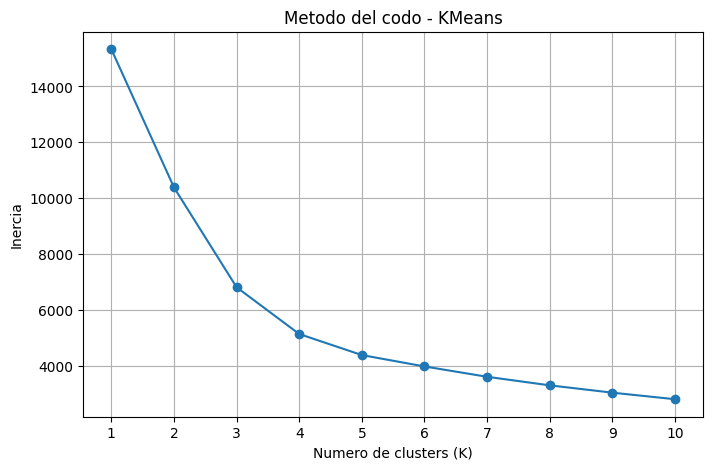

In [ ]:
#array para guardar inercias
inercias = []

valores_k = range(1, 11)

for k in valores_k:
  modelo = KMeans( n_clusters=k, random_state=42, n_init=10)

  modelo.fit(X_scaler)

  inercias.append(modelo.inertia_)

#graficar modelo del codo
plt.figure(figsize=(8, 5))
plt.plot(valores_k, inercias, marker="o")
plt.title("Metodo del codo - KMeans")
plt.xlabel("Numero de clusters (K)")
plt.ylabel("Inercia")
plt.xticks(valores_k)
plt.grid(True)

plt.show()

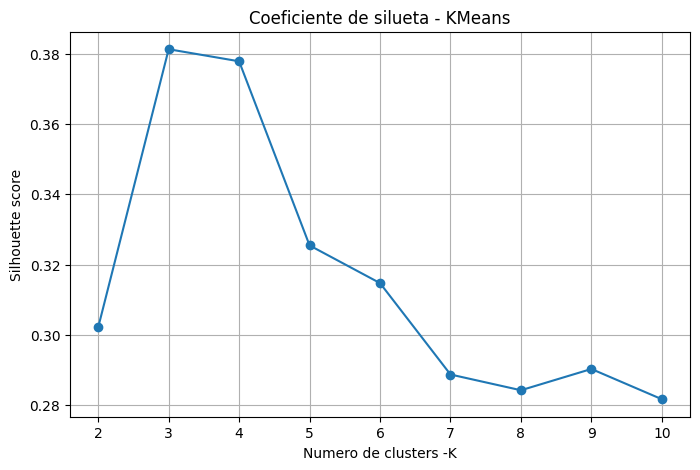

K = 2: Silueta = 0.3022
K = 3: Silueta = 0.3813
K = 4: Silueta = 0.3778
K = 5: Silueta = 0.3254
K = 6: Silueta = 0.3147
K = 7: Silueta = 0.2887
K = 8: Silueta = 0.2842
K = 9: Silueta = 0.2903
K = 10: Silueta = 0.2817


In [ ]:
#array oara coeficientes de silueta
siluetas= []

valores_k_silueta = range(2, 11)

for k in valores_k_silueta:
  modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
  etiquetas = modelo.fit_predict(X_scaler)
  puntuacion = silhouette_score(X_scaler, etiquetas, sample_size=2000, random_state=42)
  siluetas.append(puntuacion)


#grafica
plt.figure(figsize=(8, 5))
plt.plot(valores_k_silueta, siluetas, marker="o")
plt.title("Coeficiente de silueta - KMeans")
plt.xlabel("Numero de clusters -K")
plt.ylabel("Silhouette score")
plt.xticks(valores_k_silueta)
plt.grid(True)

plt.show()

for k, puntuacion in zip(valores_k_silueta, siluetas):
  print(f"K = {k}: Silueta = {puntuacion:.4f}")

In [ ]:
#numero optimo de clusters
k_optimo = 3

#modelo final
modelo_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)

#entrenar y ontener etiquetas finales
etiquetas_clusters = modelo_final.fit_predict(X_scaler)

#hacer copia de datos de los clusters
datos_resultados = X.copy()
datos_resultados["cluster"] = etiquetas_clusters

datos_resultados.head()



,age,avg_glucose_level,bmi,cluster
0,67.0,228.69,36.6,2
1,61.0,202.21,28.1,2
2,80.0,105.92,32.5,0
3,49.0,171.23,34.4,2
4,79.0,174.12,24.0,2


In [ ]:
#pecientes por cluster
print(datos_resultados["cluster"].value_counts().sort_index())

cluster
0    2684
1    1727
2     699
Name: count, dtype: int64


In [ ]:
#obtener centroides en StandardSCaler
centroides_scaled = modelo_final.cluster_centers_

#los convertimos a sus unidades originales
centroides_originales = scaler.inverse_transform(
    centroides_scaled
)

#tabla de interpretacion
tabla_centroides = pd.DataFrame( centroides_originales, columns = caracteristicas)

tabla_centroides.index.name = "cluster"

display(tabla_centroides.round(2))

,age,avg_glucose_level,bmi
cluster,,,
0,54.34,88.98,31.68
1,19.02,92.71,22.86
2,60.41,205.11,32.90


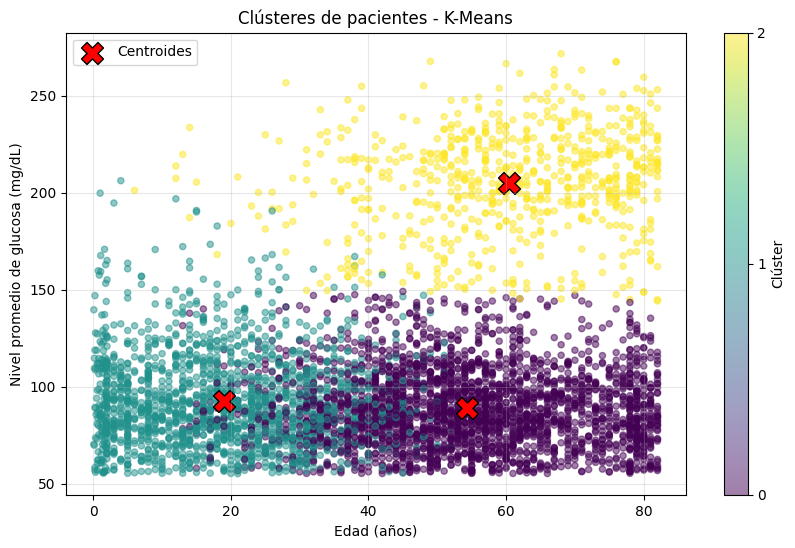

In [ ]:
#grafica de dispersion
plt.figure(figsize=(10, 6))

# Graficamos a los pacientes
scatter = plt.scatter(
    datos_resultados["age"],
    datos_resultados["avg_glucose_level"],
    c=datos_resultados["cluster"],
    cmap="viridis",
    alpha=0.5,
    s=20
)

# Graficamos los centroides
plt.scatter(
    tabla_centroides["age"],
    tabla_centroides["avg_glucose_level"],
    c="red",
    marker="X",
    s=250,
    edgecolors="black",
    label="Centroides"
)

# Configuración de la gráfica
plt.title("Clústeres de pacientes - K-Means")
plt.xlabel("Edad (años)")
plt.ylabel("Nivel promedio de glucosa (mg/dL)")

plt.colorbar(scatter, ticks=[0, 1, 2], label="Clúster")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [ ]:
# Resumen de las características por clúster
resumen_clusters = datos_resultados.groupby("cluster").agg(
    pacientes=("age", "size"),
    edad_promedio=("age", "mean"),
    glucosa_promedio=("avg_glucose_level", "mean"),
    bmi_promedio=("bmi", "mean")
)

display(resumen_clusters.round(2))


,pacientes,edad_promedio,glucosa_promedio,bmi_promedio
cluster,,,,
0,2684,54.33,89.00,31.68
1,1727,19.01,92.72,22.86
2,699,60.43,205.19,32.89


In [ ]:
#copia de resultados de clustering
datos_validacion = datos_resultados.copy()

#recuperar stroke
datos_validacion["stroke"] = stroke_real

datos_validacion.head()

,age,avg_glucose_level,bmi,cluster,stroke
0,67.0,228.69,36.6,2,1
1,61.0,202.21,28.1,2,1
2,80.0,105.92,32.5,0,1
3,49.0,171.23,34.4,2,1
4,79.0,174.12,24.0,2,1


In [ ]:
#tabla cruzada
tabla_cruzada = pd.crosstab(datos_validacion["cluster"], datos_validacion["stroke"])

#renombrar columnas
tabla_cruzada = tabla_cruzada.rename(columns={0: "Sin derrame", 1: "Con derrame"})

display(tabla_cruzada)

stroke,Sin derrame,Con derrame
cluster,,
0,2530,154
1,1723,4
2,608,91


In [ ]:
# Calculamos las proporciones por clúster
tabla_proporciones = pd.crosstab(
    datos_validacion["cluster"],
    datos_validacion["stroke"],
    normalize="index"
) * 100

# Renombramos las columnas
tabla_proporciones = tabla_proporciones.rename(
    columns={0: "Sin derrame", 1: "Con derrame"}
)

print("Porcentaje de casos por clúster:")
display(tabla_proporciones.round(2))


Porcentaje de casos por clúster:


stroke,Sin derrame,Con derrame
cluster,,
0,94.26,5.74
1,99.77,0.23
2,86.98,13.02
